# TS-SatFire: TS=2·4·6 × GAM / Spatial GAM

**목적:** 같은 사건의 다음 날 **새로 기록된** 화재 영역을 예측하고, 공간 효과의 추가 기여를 비교합니다. 기존 노트북과 결과는 수정하지 않습니다.

- 사건: `US_2021_NM3323810847220210520`.
- 두 모델 모두 로지스틱 링크, 동일한 환경변수 요약과 과거 화재 이력 사용.
- Spatial GAM만 고정된 공간 Gaussian RBF 평활항을 추가하여 **이항 우도 안에서 공동 적합**.
- 이 구현은 저차원 공간 GAM입니다. GAM 잔차의 사후 크리깅, 완전한 시공간 GP, kriging 불확실성 추정은 아닙니다.
- 한 사건 안의 사후 실험입니다. 이 사건은 원 논문의 FP 시험 사건이지만 여기서는 일부 날짜로 재학습하므로 **공식 시험 성능이 아닙니다**. 이미 확인한 시험 기간을 활용한 후속 탐색이며 최종 독립 검증을 대체하지 않습니다.

`DEMO_MODE=False`가 기본입니다. 실제 GeoTIFF가 없으면 오류로 멈추며 합성 데이터로 자동 대체하지 않습니다.

## 1. 환경과 설정
아래는 **노트북 Python 셀**입니다. Bash 터미널에 직접 입력하지 마세요. 이 노트북과 `window_gam.py`, `satfire_demo.py`를 같은 폴더에 둡니다. 설치 명령은 `README_HPC.md`에 있습니다. 첫 실행 전 raw_root를 확인하세요.

입력 밴드 매핑은 기존 inventory에 맞춥니다. GDAL scale/offset만 적용하며 NDVI에 임의 배율을 추가하지 않습니다. 구름 QA가 없으므로 결측을 구름으로 간주하지 않습니다. 예보 밴드는 기본 실험에서 제외합니다.

In [1]:
from pathlib import Path
import os, sys, json
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display

BUNDLE_DIR = Path.cwd()  # 필요하면 이 노트북/helper가 있는 절대경로로 변경
assert (BUNDLE_DIR / "window_gam.py").exists(), "BUNDLE_DIR를 helper 폴더로 지정하세요."
sys.path.insert(0, str(BUNDLE_DIR))
import window_gam as wg

DEMO_MODE = True
CFG = wg.defaults()
CFG["raw_root"] = os.environ.get("TS_SATFIRE_RAW_ROOT", "/home/jlc3q/data/SatFire/ts-satfire")
CFG["event_id"] = "US_2021_NM3323810847220210520"
# 기존 사건 감사에서 채택한 사후 '기록 화재' 라벨 정책. 물리적 무화재와 다릅니다.
CFG["label_nan_policy"] = "legacy_nan_zero"
CFG["timing_note"] = "사후 기록 화재 확산 실험. 원천 제품의 당시 공개 시각은 검증되지 않았으며 운영 예측으로 해석하지 않음."

if DEMO_MODE:
    from satfire_demo import make_demo
    CFG.update(raw_root=str(BUNDLE_DIR / "demo_data"), event_id="SYNTHETIC_ONLY",
               features=["ndvi", "i4", "tmax"], negative_keep=1.,
               lambdas=[0.001, 0.01], spatial_lengths_km=[3.], spatial_knots_side=3,
               n_knots=3, max_iter=2000)
    make_demo(CFG["raw_root"], CFG["event_id"])

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = BUNDLE_DIR / "runs" / (("demo_" if DEMO_MODE else "real_") + stamp)
print("SYNTHETIC TEST ONLY" if DEMO_MODE else "RETROSPECTIVE REAL-EVENT EXPERIMENT")
print("Source:", Path(CFG["raw_root"]) / CFG["event_id"])
print("Output:", OUT)

SYNTHETIC TEST ONLY
Source: /private/tmp/satfire_window_notebook_check/demo_data/SYNTHETIC_ONLY
Output: /private/tmp/satfire_window_notebook_check/runs/demo_20261120T182442189356Z


## 2. 자료 감사와 공통 날짜·픽셀 고정
전체 날짜를 앞 50% / 다음 25% / 나머지의 시간 블록으로 나눕니다. 각 블록의 첫 6일은 입력 확보용으로만 쓰고, 이후 날짜를 **모든 TS에 공통인 target 날짜**로 지정합니다. 날짜 수나 양성 수를 보고 분할을 다시 고르지 않습니다.

38일(2021-05-17–06-23)일 경우 예상 target은 train 05-23–06-04 (13일), val 06-11–06-13 (3일), test 06-20–06-23 (4일)입니다. 파일이 다른 경우 아래 실제 manifest가 기준입니다.

각 target 날짜 d에서 `C(d-1)=0`이고 이전/현재 라벨 상태를 알 수 있는 픽셀만 평가합니다. 타겟은 `C(d) & ~C(d-1)`이며, C는 AF 또는 BA의 양성 기록 누적입니다. `legacy_nan_zero`에서 NaN은 '양성 기록 없음'입니다. 파일 누락·격자 불일치는 중단합니다. strict_unknown은 별도 민감도 실험이며 이번 사건에서 많은 픽셀이 평가 불가능할 수 있습니다.

공통 평가 픽셀은 라벨 가용성으로 정하며 설명변수의 결측 여부로 제외하지 않습니다. 전체 날짜의 inventory는 품질 감사용이며 모델 전처리의 fitting에는 사용하지 않습니다.

In [2]:
data = wg.prepare(CFG, OUT)
display(data["manifest"])
summary = data["manifest"].groupby("split", sort=False).agg(
    targets=("target_date", "size"), first_target=("target_date", "min"),
    last_target=("target_date", "max"), pixels=("n", "sum"), positives=("positives", "sum"))
display(summary)
display(pd.read_csv(OUT / "inventory.csv").groupby(["product", "band"]).agg(
    finite_fraction_min=("finite_fraction", "min"), value_min=("minimum", "min"), value_max=("maximum", "max")))
print("Raster nodata is NOT a cloud QA mask.")

,split,target_date,input_start_TS6,last_input,n,positives,pixel_sha256
0,train,2021-05-07,2021-05-01,2021-05-06,670,0,15e1bfa1a50cfa4c955866162232afc79fa207e2571f4c...
1,train,2021-05-08,2021-05-02,2021-05-07,670,19,15e1bfa1a50cfa4c955866162232afc79fa207e2571f4c...
2,train,2021-05-09,2021-05-03,2021-05-08,651,0,8259def8168645f10e8450535e1248d50f47abc627641f...
3,train,2021-05-10,2021-05-04,2021-05-09,651,19,8259def8168645f10e8450535e1248d50f47abc627641f...
4,train,2021-05-11,2021-05-05,2021-05-10,632,0,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
5,train,2021-05-12,2021-05-06,2021-05-11,632,0,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
6,train,2021-05-13,2021-05-07,2021-05-12,632,19,90977d5a8dabba1bbe4286bf1b14c55b0e6d4cf17cd484...
7,train,2021-05-14,2021-05-08,2021-05-13,613,0,c5a6c9b405a973db2c62e30595ac1703d9309043e1403c...
8,train,2021-05-15,2021-05-09,2021-05-14,613,19,c5a6c9b405a973db2c62e30595ac1703d9309043e1403c...
9,train,2021-05-16,2021-05-10,2021-05-15,594,0,a87a9f1e66c303cdcbfb15fe666c55ee9af05eea473704...


,targets,first_target,last_target,pixels,positives
split,,,,,
train,14,2021-05-07,2021-05-20,8658,114
val,4,2021-05-27,2021-05-30,1958,38
test,4,2021-06-06,2021-06-09,1616,38


finite_fraction_min   value_min  value_max
product   band                                            
FirePred  1                0.954082    0.239228    0.64886
          2                1.000000    0.239228    0.64886
          3                1.000000    0.239228    0.64886
          4                1.000000    0.239228    0.64886
          5                1.000000    0.239228    0.64886
          6                1.000000    0.239228    0.64886
          7                1.000000   20.000000   25.82000
          8                1.000000    0.239228    0.64886
          9                1.000000    0.239228    0.64886
          10               1.000000    0.239228    0.64886
          11               1.000000    0.239228    0.64886
          12               1.000000    0.239228    0.64886
          13               1.000000    0.239228    0.64886
          14               1.000000    0.239228    0.64886
          15               1.000000    0.239228    0.64886
          16               1.000000    0.239228    0.64886
          17               1.000000    0.239228    0.64886
          18               1.000000    0.239228    0.64886
          19               1.000000    0.239228    0.64886
VIIRS_Day 1                1.000000    0.239228    0.64886
          2                1.000000    0.239228    0.64886
          3                1.000000    0.239228    0.64886
          4                0.984694  290.000000  328.00000
          5                1.000000    0.239228    0.64886
          6                1.000000    0.239228    0.64886
          7                0.998724    0.000000    1.00000
          8                0.998724    0.000000    1.00000

Raster nodata is NOT a cloud QA mask.


## 3. 모델과 누수 방지 규칙
각 연속 변수에 대해 입력 TS일의 마지막 값, 유효값 평균, 마지막−첫 값, 결측 비율을 계산합니다. 풍향은 sin/cos로 바꾼 뒤 요약합니다. 두 모델 모두 t일의 누적 기록 화재까지 거리(픽셀), 5×5 기록 화재 비율, 최근 증가 영역의 5×5 비율을 사용합니다. **각 일자를 독립 lag 변수로 넣는 모델이 아니므로 원 논문의 신경망 TS 실험을 재현하지 않습니다.**

\[
y(s,t+1)\sim\mathrm{Bernoulli}(p),\qquad
\operatorname{logit}(p)=\beta_0+\sum_j B_j(x_{j,TS})\beta_j
+\underbrace{\sum_k u_k\exp[-\|s-c_k\|^2/(2\ell^2)]}_{\text{Spatial GAM only}}.
\]

환경항은 cubic B-spline, 공간항은 지역 AEQD 좌표(km)의 Gaussian RBF입니다. 학습 자료에서만 환경 spline 범위, 결측 중앙값, 표준화와 공간 knot 범위를 정합니다. 계수에는 ridge 페널티를 쓰며 표준 GAM의 2차 차분 roughness penalty와는 다릅니다. 공간항은 시간에 고정된 패턴이고, 확산 방향을 동적으로 추정하는 모델이 아닙니다.

최적화 목표는 `weighted mean Bernoulli NLL + λ/2 × (||β||² + ratio ||u||²)`입니다. 절편은 벌점이 없습니다. 공간 길이와 λ는 validation log loss로 선택합니다. 이 실험의 λ/공간 길이 후보는 기본 설정에서 사전 고정되어 있습니다.

- 모델 학습은 train만, 모델·임계값 선택은 val만, 마지막 평가는 test만 사용합니다.
- 누적 화재 상태는 사건 시작부터 **예측 전날까지** 업데이트합니다. 이전 검증/시험일의 관측도 그 다음 날에는 사용합니다. 이는 매일 관측을 받는 **one-step rolling-origin** 실험이며, 시험 시작 시점에서 여러 날을 한꺼번에 예측하는 실험이 아닙니다.
- 블록 간 TS 입력 영상은 겹치지 않지만, 누적 화재 상태는 과거 관측을 이어받습니다. 독립 사건/공간 holdout은 아닙니다.
- kriging 결측 복원은 하지 않습니다. 공통 train-only 중앙값으로 채우고 결측 비율을 사용하여 공간 효과의 기여를 분리합니다.
- 모든 양성과 음성의 5%를 동일하게 추출하여 6모델에서 공유합니다. 음성 가중치 20은 표본추출 보정이며 `class_weight='balanced'`를 쓰지 않습니다. 실제 확률 보정 정도는 시험 Brier/log loss/calibration으로 확인합니다.
- F1 임계값은 검증 자료에서만 선택합니다. 검증 기간에 두 클래스가 없으면 중단하며 날짜를 자동 재선택하지 않습니다.

In [3]:
# 입력 영상/타겟 날짜의 블록 간 중복 검증 (누적 과거 상태는 위 설명처럼 공유 가능)
used = {}
for split, dates in data["targets"].items():
    used[split] = set()
    for d in dates:
        i = data["days"].index(d)
        used[split].update(data["days"][i-max(CFG["windows"]):i+1])
assert not (used["train"] & used["val"] or used["train"] & used["test"] or used["val"] & used["test"])
assert CFG["timing_note"].strip() and CFG["label_note"].strip()
print("Passed: three disjoint raster-date blocks; all TS share target/pixel manifest.")

Passed: three disjoint raster-date blocks; all TS share target/pixel manifest.


## 4. Train → validation 선택
CPU로 실행합니다. 실제 사건은 spline 행렬 크기와 후보 수 때문에 시간이 걸릴 수 있습니다. HPC Jupyter 작업에 CPU 4개, RAM 32 GB 이상을 시작점으로 잡고 사용량을 확인하세요. 이는 측정된 요구량이 아닙니다. 스레드 수는 README의 환경변수로 제한합니다. 매 fit 로그가 출력되고 `tuning.csv`에 진행 결과를 남깁니다. 수렴하지 않은 후보는 제외하고 전부 실패하면 중단합니다.

In [4]:
selected = wg.train_select(data)
display(pd.read_csv(OUT / "tuning.csv"))
display(pd.DataFrame(json.loads((OUT / "selection_before_test.json").read_text())))

TS=2 GAM lambda=0.001 spatial_length=None


TS=2 GAM lambda=0.01 spatial_length=None


TS=2 SpatialGAM lambda=0.001 spatial_length=3.0


TS=2 SpatialGAM lambda=0.01 spatial_length=3.0


TS=4 GAM lambda=0.001 spatial_length=None


TS=4 GAM lambda=0.01 spatial_length=None


... (4 outputs left out)

TS=6 SpatialGAM lambda=0.001 spatial_length=3.0


TS=6 SpatialGAM lambda=0.01 spatial_length=3.0


,ts,model,lam,length_km,status,val_log_loss
0,2,GAM,0.001,NaN,converged,0.039823
1,2,GAM,0.010,NaN,converged,0.044461
2,2,SpatialGAM,0.001,3.0,converged,0.029090
3,2,SpatialGAM,0.010,3.0,converged,0.037995
4,4,GAM,0.001,NaN,converged,0.040019
5,4,GAM,0.010,NaN,converged,0.045185
6,4,SpatialGAM,0.001,3.0,converged,0.029298
7,4,SpatialGAM,0.010,3.0,converged,0.038695
8,6,GAM,0.001,NaN,converged,0.040099
9,6,GAM,0.010,NaN,converged,0.045183


,key,ts,model,lam,length_km,threshold,val_log_loss
0,TS2_GAM,2,GAM,0.001,NaN,0.615760,0.039823
1,TS2_SpatialGAM,2,SpatialGAM,0.001,3.0,0.746652,0.029090
2,TS4_GAM,4,GAM,0.001,NaN,0.611615,0.040019
3,TS4_SpatialGAM,4,SpatialGAM,0.001,3.0,0.684208,0.029298
4,TS6_GAM,6,GAM,0.001,NaN,0.633101,0.040099
5,TS6_SpatialGAM,6,SpatialGAM,0.001,3.0,0.764021,0.029264


## 5. 고정된 모델의 공통 test 평가
`selection_before_test.json`이 저장된 뒤 시험 예측을 만듭니다. 시험 결과를 보고 후보·변수·임계값을 바꾸면 새로운 탐색 실험으로 기록해야 합니다. 픽셀 수와 pixel-ID SHA256을 공통 manifest와 대조합니다.

주 지표: AP, Brier, log loss. 보조 지표: ROC-AUC와 검증 임계값에서 F1/IoU/precision/recall. 전체 픽셀 평가 외 날짜별 결과와 확률 calibration을 저장합니다. 공간 모델−GAM 차이에서 AP/F1는 양수, Brier/log loss는 음수가 개선입니다. 시험일이 4일뿐이므로 통계적 유의성이나 독립 사건 일반화는 주장하지 않습니다.

In [5]:
test_metrics = wg.evaluate(data, selected)
display(test_metrics)
display(pd.read_csv(OUT / "paired_model_differences.csv"))
display(pd.read_csv(OUT / "test_metrics_by_date.csv"))
print("Constant baseline:", json.loads((OUT / "constant_baseline.json").read_text()))

,key,ts,model,threshold,n,positives,prevalence,ap,roc_auc,brier,log_loss,precision,recall,f1,iou
0,TS2_GAM,2,GAM,0.615760,1616,38,0.023515,0.223313,0.962111,0.026320,0.073063,0.095238,0.105263,0.100000,0.052632
1,TS2_SpatialGAM,2,SpatialGAM,0.746652,1616,38,0.023515,0.288343,0.972984,0.022548,0.064095,0.000000,0.000000,0.000000,0.000000
2,TS4_GAM,4,GAM,0.611615,1616,38,0.023515,0.231623,0.963828,0.025457,0.070924,0.054054,0.052632,0.053333,0.027397
3,TS4_SpatialGAM,4,SpatialGAM,0.684208,1616,38,0.023515,0.306118,0.974868,0.021424,0.061316,0.090909,0.052632,0.066667,0.034483
4,TS6_GAM,6,GAM,0.633101,1616,38,0.023515,0.217365,0.960693,0.027683,0.076671,0.086957,0.105263,0.095238,0.050000
5,TS6_SpatialGAM,6,SpatialGAM,0.764021,1616,38,0.023515,0.290415,0.972900,0.023873,0.068096,0.000000,0.000000,0.000000,0.000000


,ts,delta_AP,delta_Brier,delta_log_loss,delta_F1
0,2,0.065030,-0.003772,-0.008968,-0.100000
1,4,0.074495,-0.004033,-0.009608,0.013333
2,6,0.073050,-0.003810,-0.008575,-0.095238


,key,date,n,positives,prevalence,ap,roc_auc,brier,log_loss,precision,recall,f1,iou
0,TS2_GAM,2021-06-06,423,19,0.044917,0.392812,0.966780,0.030878,0.087615,0.285714,0.210526,0.242424,0.137931
1,TS2_GAM,2021-06-07,404,0,0.000000,NaN,NaN,0.017576,0.048632,0.000000,0.000000,0.000000,0.000000
2,TS2_GAM,2021-06-08,404,19,0.047030,0.330123,0.952973,0.036759,0.100693,0.000000,0.000000,0.000000,0.000000
3,TS2_GAM,2021-06-09,385,0,0.000000,NaN,NaN,0.019533,0.053717,0.000000,0.000000,0.000000,0.000000
4,TS2_SpatialGAM,2021-06-06,423,19,0.044917,0.488816,0.976811,0.025343,0.073785,0.000000,0.000000,0.000000,0.000000
5,TS2_SpatialGAM,2021-06-07,404,0,0.000000,NaN,NaN,0.015525,0.043143,0.000000,0.000000,0.000000,0.000000
6,TS2_SpatialGAM,2021-06-08,404,19,0.047030,0.397437,0.965824,0.030884,0.087842,0.000000,0.000000,0.000000,0.000000
7,TS2_SpatialGAM,2021-06-09,385,0,0.000000,NaN,NaN,0.018099,0.050516,0.000000,0.000000,0.000000,0.000000
8,TS4_GAM,2021-06-06,423,19,0.044917,0.459709,0.974075,0.027156,0.078167,0.222222,0.105263,0.142857,0.076923
9,TS4_GAM,2021-06-07,404,0,0.000000,NaN,NaN,0.017869,0.049126,0.000000,0.000000,0.000000,0.000000


Constant baseline: {'train_prevalence': 0.013167013167013167, 'n': 1616, 'positives': 38, 'prevalence': 0.023514851485148515, 'ap': 0.023514851485148515, 'roc_auc': 0.5, 'brier': 0.023068981002638194, 'log_loss': 0.11476305113772227, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'iou': 0.0}


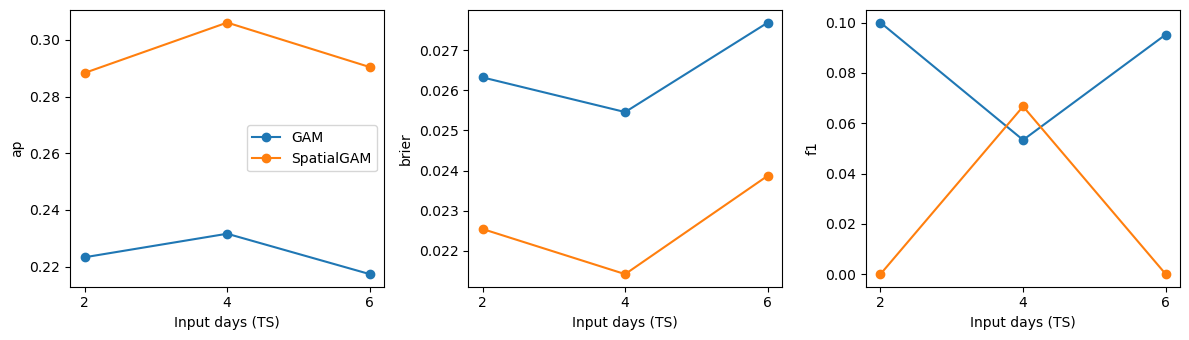

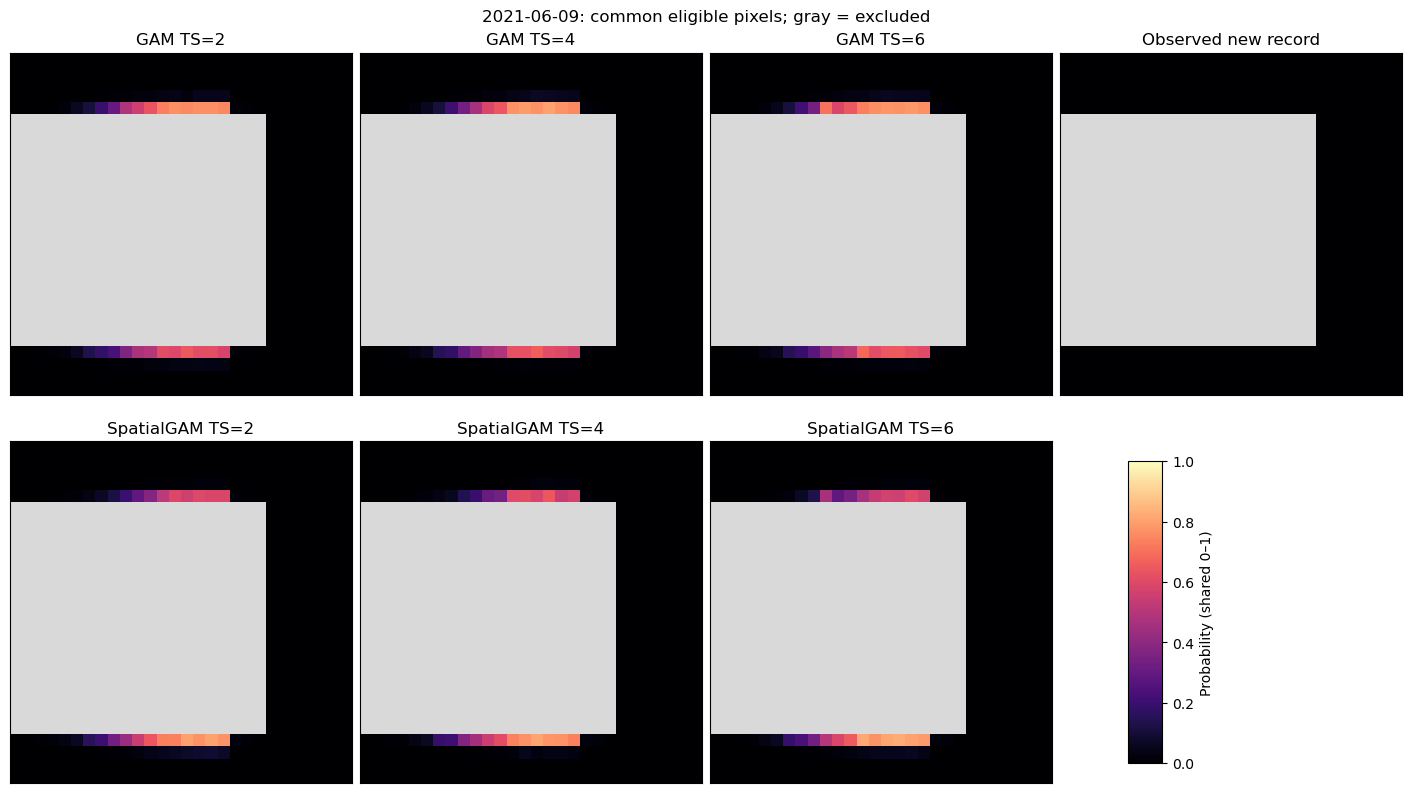

,key,bin,n,mean_prediction,observed_fraction
0,TS2_GAM,0,162,7.881080e-07,0.000000
1,TS2_GAM,1,161,2.808837e-06,0.000000
2,TS2_GAM,2,162,5.565178e-06,0.000000
3,TS2_GAM,3,161,1.107179e-05,0.000000
4,TS2_GAM,4,162,2.306366e-05,0.000000
5,TS2_GAM,5,162,4.983011e-05,0.000000
6,TS2_GAM,6,161,1.168554e-04,0.000000
7,TS2_GAM,7,161,5.533742e-04,0.000000
8,TS2_GAM,8,162,1.441211e-02,0.000000
9,TS2_GAM,9,162,4.365967e-01,0.234568


Saved: /private/tmp/satfire_window_notebook_check/runs/demo_20261120T182442189356Z


In [6]:
wg.plots(data)
display(pd.read_csv(OUT / "calibration.csv"))
print("Saved:", OUT)

## 해석과 산출물
`evaluation_manifest.csv`는 공통 날짜/픽셀 식별자, `training_rows.npz`는 동일 학습 표본/가중치, `selection_before_test.json`은 시험 전 선택 결과입니다. `predictions/*.npz`에는 날짜·flat pixel ID·관측·확률을 저장합니다. `grid.json`의 shape/affine/CRS로 원 격자를 복원할 수 있습니다. NaN 영역은 예측 실패가 아니라 이미 기록 화재이거나 라벨 상태를 모르는 제외 영역입니다.

공간 모델이 개선되어도 같은 사건의 고정된 공간 패턴을 활용한 효과입니다. 일반적인 산불 발생 확률, 인체 건강 위험, 운영 예측 성능으로 해석하지 마세요. 후속 검증은 아직 보지 않은 사건과 기간에서 필요합니다.

참고: [공식 TS-SatFire 코드](https://github.com/zhaoyutim/TS-SatFire), [논문 v1](https://arxiv.org/abs/2412.11555), [학술지판](https://doi.org/10.1038/s41597-025-06271-3). TS=2·4·6 비교 아이디어를 가져왔으며 원 논문의 여러 사건 학습/2021 시험 분할, 256×256 crop, 신경망 입력·라벨 처리 전체를 복제하지 않습니다.